# Schräger Wurf

Einbinden der benötigten bibliotheken

In [16]:
import numpy as np
import matplotlib.pyplot as plt

## Programmierung der Bewegungsgleichungen

Die Formel für die Bewegung in x-Richtung lautet:
$$x(t) = v_{x,0} \cdot t \tag{1}$$
als Python-Funktion also:

In [17]:
def x(t, vx0):
    return vx0 * t

Die Formel für die y-Richtung hat allerdings noch den Beschleunigungsterm $g$ und eine Starthöhe $h$:
$$y(t) = h + v_{y,0} \cdot t - \frac{g}{2} \cdot t^2 \tag{2}$$
ebenso in Python also:

In [18]:
def y(t, h, vy0, g=9.81):
    out = h + (vy0 * t) - (g * (t**2) / 2)
    return out

## Berechnung der Startgrößen

Da hier ein schräger Wurf vorliegt, muss die Vektorielle Größe $v_0$ zunächst in seine Komponenten $v_{x,0}$ und $v_{y,0}$ unterteilt werden. Es gilt dabei:
$$v_{x,0} = \cos(\alpha) \cdot |v_0| \tag{3}$$
$$v_{y,0} = \sin(\alpha) \cdot |v_0| \tag{4}$$
Wie in $(3)$ und $(4)$ zu sehen, muss zusätzlich noch der Abwurfwinkel $\alpha$ abgefragt werden.
Folgend also der Python code dazu:

In [25]:
#Hier die Startwerte eingeben
#Betrag der Anfangsgeschwindigkeit in m/s
v0 = 5
#Abwurfwinkel in rad
alpha = np.pi / 4
#Höhe in Metern
h = 10
#Ortsfaktor g in m/s²
g = 9.81

#Berechnung der x- und y-Komponenten von v0
vx0 = np.cos(alpha) * v0
vy0 = np.sin(alpha) * v0

## Berechnung des Endpunktes

Da man nicht möchte, dass der Graph sich weiter fortsetzt, obwohl das Wurfobjekt schon aufgeschlagen ist ($y = 0$) berechnen wir hier die Werte, wann das passiert. So können wir sie später als Endwerte festlegen.

Wir müssen nun die Nullstelle der y-Bewegungsgleichung nach t finden:
$$0 = y(t) = h + v_{y,0} \cdot t - \frac{g}{2} \cdot t^2$$
Wir formen also so um, dass wir die p-q-Formel anwenden können:
$$0 = -\frac{2 \cdot h}{g} - \frac{2 \cdot v_{y,0} \cdot t}{g} + t^2$$
Und setzen in diese ein, wobei nur das positive Ergebnis von Bedeutung:
$$t_{end} = \frac{v_{y,0}}{g} + \sqrt{(\frac{v_{y,0}}{g})^2 + \frac{2 \cdot h}{g}}$$
$$t_{end} = \frac{v_{y,0}}{g} + \sqrt{ \frac{v_{y,0}^2 + 2 h \cdot g}{g^2}}$$
In code ergibt sich nun:

In [36]:
t_end = (vy0/g) + np.sqrt((vy0**2 + 2*h*g)/(g**2))
t_end

np.float64(1.83302617306398)

## Generierung der Graphen

Hier wird zunächst ein Stützarray generiert, das von $t=0$ bis zum Aufschlag eine bestimmte Anzahl an t-Werten enthält. Dann werden die Funktionen darauf angewendet um Ergebnis-arrays zu erhalten:

In [28]:
t_Array = np.linspace(0, t_end)

x_Array = x(t_Array, vx0)
y_Array = y(t_Array, h, vy0, g)

Die Arrays werden nun in einem Graphen dargestellt:

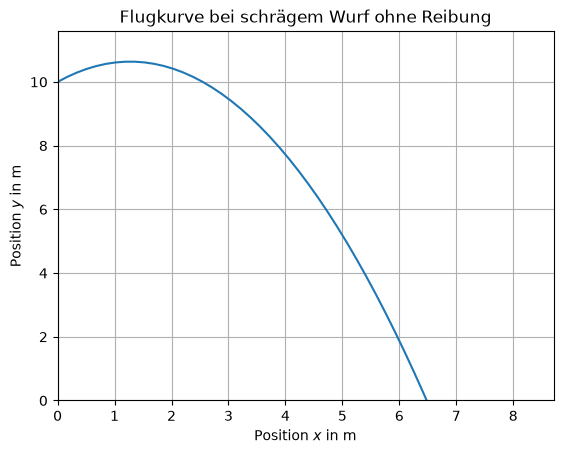

In [35]:
plt.plot(x_Array, y_Array)
plt.xlabel("Position $x$ in m")
plt.ylabel("Position $y$ in m")
plt.title("Flugkurve bei schrägem Wurf ohne Reibung")
plt.ylim(bottom=0)
plt.xlim(left=0)
plt.grid()
plt.show()